### Problem statement
System: In -> A -> B -> C

<br>

**In $\rightarrow$ A:** Transform Qubit Readout data. Messages arrive with fixed mean arrival rate $\lambda$. Infinite queue if stage A blocked.

**A:** Read message. Processing time $\mathrm{Uniform}(1.5, 2.2)\mu s$.

**A $\rightarrow$ B:** FIFO buffer. Capacity = 100. If full A stops

**B:** Log-Normal distribution processing time $\mu = 0.5 , \sigma ^2 = 0.5$

**B $\rightarrow$ C:** FIFO buffer. Capacity = 25. If full B stops

**C:** Constant time of $1.5\mu s$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Num Qubits: 4618
Mean qubit times: 4566.067393644077
Latency from enter A: 194.531080154893
A utilisation:  0.9437379998509756
B utilisation:  0.9996766998421649
C utilisation:  0.6927050998906553


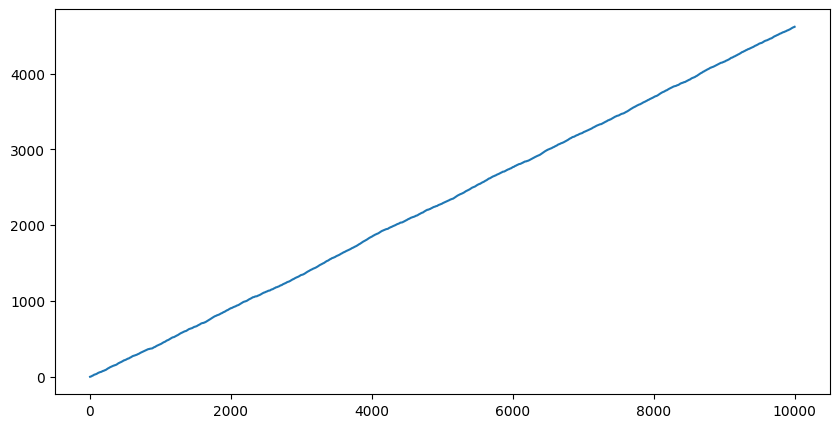

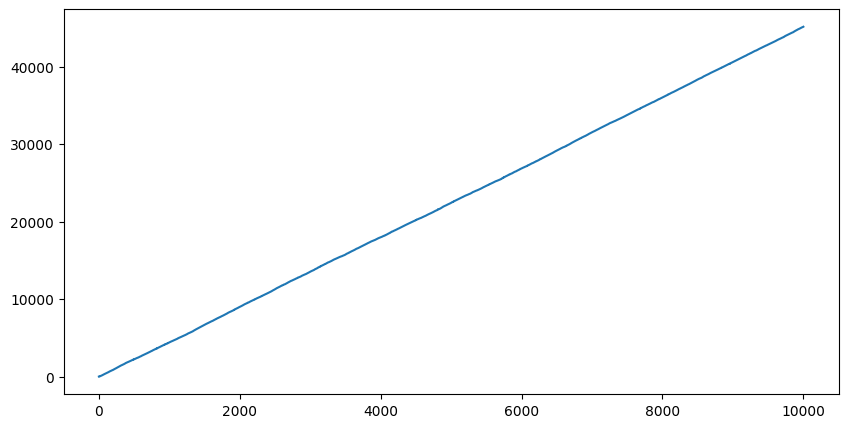

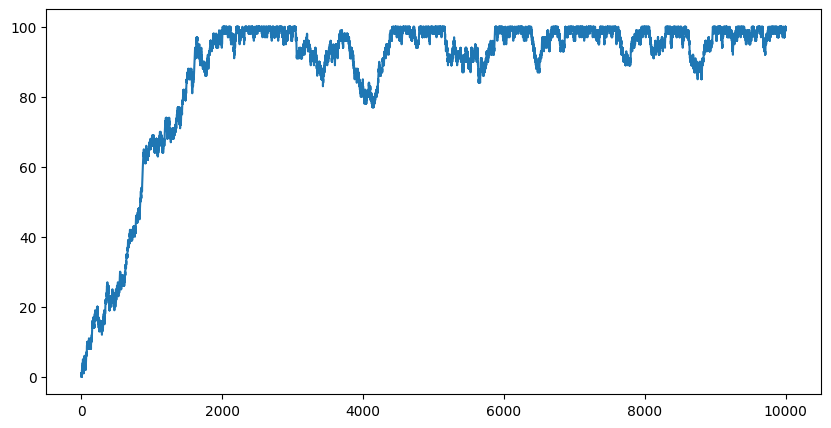

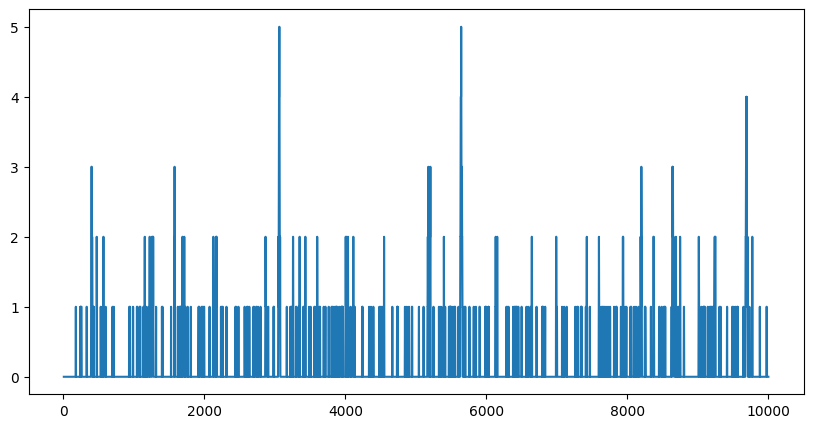

In [215]:
class Queue:
    def __init__(self, max_length):
        self.length = 0
        self.max_length = max_length

class Source:
    def __init__(self, lam):
        self.lam = lam

    def next_arrival(self):
        return np.random.exponential(scale=self.lam)

def run_sim(lam, max_time):

    b_queue = Queue(100)
    c_queue = Queue(25)
    a_queue = Queue(1e8)
        
    source = Source(lam)
    ts = 0.001
    max_time = max_time

    time = 0.0
    a_time = 0.0
    b_time = 0.0
    c_time = 0.0

    a_stopped = False
    b_stopped = False

    qubits_in_a = 0
    qubits_in_b = 0
    qubits_in_c = 0

    qubit_enter_a_times = []

    next_a_arrival = source.next_arrival()

    callbacks = {
        'a_queue_lengths': [],
        'b_queue_lengths': [],
        'c_queue_lengths': [],
        'a_time_on': 0.0,
        'b_time_on': 0.0,
        'c_time_on': 0.0,
        'qubit_in_times': [],
        'latency_from_a': 0,
        'qubit_out_times': [],
        'final_queue_lengths': [0, 0, 0],
        'total_time': 0,
        'component_utilisation': {},
        'mean_time_in_system': 0,
        'times_in_system': []
    }

    # TODO: check utilisation for last bit
    # TODO: remove utilisation when system 
    # TODO: latency should be lower. keeps increasing 
    while time < max_time:
        
        if next_a_arrival < ts:
            a_queue.length += 1
            
            # print(qubit_in)
            next_a_arrival = source.next_arrival()
            # print('IN', time, next_a_arrival)

            callbacks['qubit_in_times'] += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

        if (a_queue.length > 0) and (a_time < ts) and (not a_stopped):
            # Handles time at >3 decimal places
            extra_time = a_time

            qubits_in_a += 1
            
            a_queue.length -= 1
            a_time = np.random.random() + 1.5

            callbacks['a_time_on'] += (a_time - extra_time)
            qubit_enter_a_times += [time]
            callbacks['a_queue_lengths'] += [(a_queue.length, time)]

            if (b_queue.length < b_queue.max_length) and (qubits_in_a > 1):
                b_queue.length += 1
                callbacks['b_queue_lengths'] += [(b_queue.length, time)]
                if b_queue.length == b_queue.max_length:
                    a_stopped = True


        if (b_queue.length > 0) and (b_time < ts) and (not b_stopped):

            # Handles time at >3 decimal places
            extra_time = b_time

            qubits_in_b += 1
            b_queue.length -= 1
            callbacks['b_queue_lengths'] += [(b_queue.length, time)]
            a_stopped = False

            b_time = np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))

            callbacks['b_time_on'] += (b_time - extra_time)

            if (c_queue.length < c_queue.max_length) and (qubits_in_b > 1):
                c_queue.length += 1
                # callbacks['c_queue_lengths'] += [(c_queue.length/, time)]
                if c_queue.length == c_queue.max_length:
                    b_stopped = True


        if (c_queue.length > 0) and (c_time < ts):
            qubits_in_c += 1
            c_queue.length -= 1
            b_stopped = False

            callbacks['c_queue_lengths'] += [(c_queue.length, time)]
            c_time = 1.5
            
            callbacks['c_time_on'] += 1.5

            if qubits_in_c > 1:
                callbacks['qubit_out_times'] += [time]

        # callbacks['a_queue_lengths'] += [(a_queue.length, time)]
        # callbacks['b_queue_lengths'] += [(b_queue.length, time)]
        # callbacks['c_queue_lengths'] += [(c_queue.length, time)]

        time += ts
        next_a_arrival -= ts
        if a_time > 0:
            a_time -= ts
        if b_time > 0:
            b_time -= ts
        if c_time > 0:
            c_time -= ts

    callbacks['final_queue_lengths'][0] = a_queue.length
    callbacks['final_queue_lengths'][1] = b_queue.length
    callbacks['final_queue_lengths'][2] = c_queue.length

    callbacks['a_time_on'] -= a_time
    callbacks['b_time_on'] -= b_time
    callbacks['c_time_on'] -= c_time

    callbacks['component_utilisation']['a'] = callbacks['a_time_on']/time
    callbacks['component_utilisation']['b'] = callbacks['b_time_on']/time
    callbacks['component_utilisation']['c'] = callbacks['c_time_on']/time

    callbacks['times_in_system'] = [(callbacks['qubit_out_times'][i] - callbacks['qubit_in_times'][i]) for i in range(len(callbacks['qubit_out_times']))]
    callbacks['mean_time_in_system'] = np.mean(callbacks['times_in_system'])
    callbacks['latency_from_a'] = np.mean([(callbacks['qubit_out_times'][i] - qubit_enter_a_times[i]) for i in range(len(callbacks['qubit_out_times']))])


    return callbacks

callbacks = run_sim(0.2, 10000)

print('Num Qubits:', len(callbacks['qubit_out_times']))

print('Mean qubit times:', callbacks['mean_time_in_system'])
print('Latency from enter A:', callbacks['latency_from_a'])

print('A utilisation: ', callbacks['component_utilisation']['a'])
print('B utilisation: ', callbacks['component_utilisation']['b'])
print('C utilisation: ', callbacks['component_utilisation']['c'])


fig = plt.figure(figsize = (10, 5))
plt.plot(callbacks['qubit_out_times'], range(1, len(callbacks['qubit_out_times'])+1))
plt.show()

y, x = zip(*callbacks['a_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['b_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['c_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()


## Comments

1. B seems to be bottleneck. Everything downstream is clear
2. Maybe worth doing a plot explainig how B maxing out affects A
3. Final throughput/sec should be ~1/lambda until bottleneck appears. Plot of 1/lambda vs throughput/sec
4. May be worth doing mean time from when they enter A as opposed to when they enter the queue

In [206]:
len(callbacks['qubit_in_times']), len(callbacks['qubit_out_times']), callbacks['final_queue_lengths'][0], callbacks['final_queue_lengths'][1], callbacks['final_queue_lengths'][2]

(5020, 4663, 256, 98, 0)